# Module project: build a house-price model with a learned map

This notebook builds the whole project, file by file, exactly as the lesson does. Run it from top to bottom in Google Colab or Jupyter: each `%%writefile` cell writes one file of the project, and each `!python` cell runs it. Then try the ideas under **Make it yours**.

Better still: type the files yourself in your own editor, and use this notebook to check your work.

## Attachments and data

- **Notebook**: `project-5-house-prices.ipynb`, attached to this lesson and saved on your device with the course. It builds and runs the whole project. Open it in one click in Google Colab (free, nothing to install): [Open in Colab](https://colab.research.google.com/github/mahmoudyosrimahmoud13/inpace-library/blob/main/courses/bishop-dl-1-foundations/files/project-5-house-prices.ipynb). Or open the saved copy on your device with Jupyter or VS Code.
- **Finished code**: the `projects/house-prices` folder in the course files, to check your work.
- **Data**: California housing, 1990 census (StatLib, via Aurélien Géron's handson-ml2). Source: [https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv](https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv) · about: [https://github.com/ageron/handson-ml2](https://github.com/ageron/handson-ml2) · licence: public data (StatLib); repository Apache-2.0. `data.py` downloads it the first time you run it and keeps it in `data/`: `housing.csv`, 1.4 MB.

In [ ]:
%pip install -q torch pandas matplotlib

Chapter 4 says that a model can be **linear in its weights** and still very flexible, if you feed it the right basis
functions. In this project you see how far that goes on a classic real data set: predicting house values across
California. Your model will learn, on its own, a map of where houses are expensive, and you'll train it two ways: the
exact closed-form solution, and stochastic gradient descent, the way every network later in the book is trained.

The notebook attached above builds and runs the whole project; the reference code is in the course files under
`projects/house-prices`.

## What you'll build

```mermaid
flowchart LR
    A[20,433 California<br/>districts, 1990 census] --> B[data.py<br/>features + location,<br/>standardized]
    B --> C[basis.py<br/>144 Gaussian bumps<br/>over the map]
    C --> D[train.py<br/>closed form,<br/>choose lambda, test once]
    C --> E[sgd.py<br/>same model,<br/>mini-batch SGD]
    D --> F[price_map.py<br/>what the bumps learned]
```

## Set up the project

```bash
mkdir house-prices && cd house-prices
python -m venv .venv && source .venv/bin/activate
pip install torch pandas matplotlib
git init
```

```text
house-prices/
    .gitignore
    README.md
    basis.py
    data.py
    model.pt
    price_map.py
    requirements.txt
    sgd.py
    train.py
```

In [2]:
%%writefile requirements.txt
torch
pandas
matplotlib

Writing requirements.txt


In [3]:
%%writefile .gitignore
data/
outputs/
__pycache__/
.venv/

Writing .gitignore


## Step 1: the data

Each row is a census district: its median income, the age of its houses, the number of rooms and people, its location,
and the target, its median house value. A little **feature engineering** makes the raw counts meaningful: rooms per
house instead of total rooms in the district, the share of rooms that are bedrooms, people per house.

Two warnings worth writing in your README: values are capped at $500k (985 districts sit exactly at the cap, so the
model can't learn how expensive they really are), and the data is from 1990, so it says nothing about prices today.

In [4]:
%%writefile data.py
"""California housing (1990 census): 20,640 districts, their median house value and 8 facts about them."""
from pathlib import Path
import pandas as pd
import torch

URL = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"
CACHE = Path("data/housing.csv")
FEATURES = ["median_income", "housing_median_age", "rooms_per_house", "bedroom_share", "people_per_house"]


def load_table():
    if not CACHE.exists():
        CACHE.parent.mkdir(exist_ok=True)
        pd.read_csv(URL).to_csv(CACHE, index=False)
    t = pd.read_csv(CACHE).dropna()
    t["rooms_per_house"] = t.total_rooms / t.households
    t["bedroom_share"] = t.total_bedrooms / t.total_rooms
    t["people_per_house"] = (t.population / t.households).clip(upper=10)   # a few districts are hotels or dorms
    t["value"] = t.median_house_value / 1000                              # in thousands of dollars
    return t


def load_splits(seed=0):
    t = load_table()
    order = torch.randperm(len(t), generator=torch.Generator().manual_seed(seed))
    n_train, n_val = int(0.6 * len(t)), int(0.2 * len(t))
    idx = {"train": order[:n_train], "val": order[n_train:n_train + n_val], "test": order[n_train + n_val:]}
    X = torch.tensor(t[FEATURES].values, dtype=torch.float32)
    loc = torch.tensor(t[["latitude", "longitude"]].values, dtype=torch.float32)
    y = torch.tensor(t["value"].values, dtype=torch.float32)
    mean, std = X[idx["train"]].mean(0), X[idx["train"]].std(0)       # training statistics only
    X = (X - mean) / std
    return {k: (X[i], loc[i], y[i]) for k, i in idx.items()}


if __name__ == "__main__":
    t = load_table()
    print(f"{len(t)} districts; median house value from ${t.value.min():.0f}k to ${t.value.max():.0f}k")
    print(f"districts at the cap of $500k: {(t.median_house_value >= 500000).sum()}")
    print(t[FEATURES + ["value"]].describe().loc[["mean", "std"]].round(2).T)

Writing data.py


In [5]:
!python data.py

20433 districts; median house value from $15k to $500k
districts at the cap of $500k: 985
                      mean     std
median_income         3.87    1.90
housing_median_age   28.63   12.59
rooms_per_house       5.43    2.48
bedroom_share         0.21    0.06
people_per_house      2.93    0.82
value               206.86  115.44


## Step 2: basis functions over the map

Location surely matters, but how? Price doesn't rise steadily as you go north or west: it jumps near the coast and in a
few cities. A linear function of latitude and longitude can't express that.

Section 4.1.1's answer: replace the raw inputs with **basis functions**. We place a 12 × 12 grid of Gaussian bumps over
California. Each one measures "how close is this district to my centre?", and the model learns one weight per bump.
Together they can draw any smooth surface, and the model is still linear in its weights, so equation 4.27 solves it
exactly:

```text
w = (λI + ΦᵀΦ)⁻¹ Φᵀ t
```

In [6]:
%%writefile basis.py
"""Basis functions (Bishop, section 4.1.1): the model stays linear in its weights, but not in its inputs."""
import torch


class LocationBasis:
    """Gaussian bumps on a grid over California: phi_j(location) = exp(-|location - centre_j|^2 / (2 s^2))."""
    def __init__(self, n=12, s=0.5):
        lat = torch.linspace(32.5, 42.0, n)
        lon = torch.linspace(-124.3, -114.3, n)
        self.centres = torch.cartesian_prod(lat, lon)             # n * n centres, in degrees
        self.s = s

    def __call__(self, loc):
        return torch.exp(-torch.cdist(loc, self.centres) ** 2 / (2 * self.s ** 2))


def design(X, loc, basis=None):
    """The design matrix Phi (equation 4.15): a column of ones for the bias, the features, and the basis functions."""
    cols = [torch.ones(len(X), 1), X]
    if basis is not None:
        cols.append(basis(loc))
    return torch.cat(cols, dim=1)


def fit_closed_form(Phi, y, lam):
    """Regularized least squares (equation 4.27): w = (lam I + Phi^T Phi)^-1 Phi^T y. The bias is not penalized."""
    penalty = lam * torch.eye(Phi.shape[1])
    penalty[0, 0] = 0
    return torch.linalg.solve(Phi.T @ Phi + penalty, Phi.T @ y)


def rmse(Phi, w, y):
    return ((Phi @ w - y) ** 2).mean().sqrt().item()

Writing basis.py


## Step 3: compare, choose, test

In [7]:
%%writefile train.py
"""Compare models on the validation set, choose lambda, then test the final model once."""
import torch
from data import load_splits
from basis import LocationBasis, design, fit_closed_form, rmse

d = load_splits()
(Xtr, Ltr, ytr), (Xva, Lva, yva), (Xte, Lte, yte) = d["train"], d["val"], d["test"]
print(f"always guess the average:     validation RMSE ${((yva - ytr.mean()) ** 2).mean().sqrt():.1f}k")

w = fit_closed_form(design(Xtr, Ltr), ytr, 0.0)
print(f"linear in the 5 features:     validation RMSE ${rmse(design(Xva, Lva), w, yva):.1f}k")

Phi_raw = lambda X, L: design(torch.cat([X, (L - Ltr.mean(0)) / Ltr.std(0)], 1), L)
w = fit_closed_form(Phi_raw(Xtr, Ltr), ytr, 0.0)
print(f"+ latitude and longitude:     validation RMSE ${rmse(Phi_raw(Xva, Lva), w, yva):.1f}k")

print("\n+ 144 Gaussian basis functions over the map:")
basis = LocationBasis()
P_tr, P_va = design(Xtr, Ltr, basis), design(Xva, Lva, basis)
scores = {}
for lam in [0.0, 0.01, 0.1, 1.0, 10.0, 100.0]:
    try:
        w = fit_closed_form(P_tr, ytr, lam)
    except torch.linalg.LinAlgError:
        print(f"  lambda {lam:<6g} cannot be solved: the matrix is singular")
        continue
    scores[lam] = rmse(P_va, w, yva)
    print(f"  lambda {lam:<6g} train RMSE ${rmse(P_tr, w, ytr):.1f}k   validation RMSE ${scores[lam]:.1f}k")
lam = min(scores, key=scores.get)

# Final model: refit on train + validation with the chosen lambda, then the test set, once
X = torch.cat([Xtr, Xva]); L = torch.cat([Ltr, Lva]); y = torch.cat([ytr, yva])
w = fit_closed_form(design(X, L, basis), y, lam)
print(f"\nchosen lambda = {lam:g}. TEST RMSE ${rmse(design(Xte, Lte, basis), w, yte):.1f}k")
torch.save({"w": w, "lam": lam}, "model.pt")

Writing train.py


In [8]:
!python train.py

always guess the average:     validation RMSE $115.2k
linear in the 5 features:     validation RMSE $74.6k
+ latitude and longitude:     validation RMSE $68.3k

+ 144 Gaussian basis functions over the map:


  lambda 0      cannot be solved: the matrix is singular


  lambda 0.01   train RMSE $61.1k   validation RMSE $61.4k


  lambda 0.1    train RMSE $61.2k   validation RMSE $61.5k


  lambda 1      train RMSE $61.5k   validation RMSE $61.7k


  lambda 10     train RMSE $62.4k   validation RMSE $62.5k


  lambda 100    train RMSE $64.0k   validation RMSE $64.2k



chosen lambda = 0.01. TEST RMSE $61.0k


Each step down the list earns its place:

- The five district features cut the error from $115k to $75k (income does most of the work).
- Adding latitude and longitude as plain numbers helps a little ($68k).
- The 144 bumps bring it to $61k: the model can now say "this particular area is expensive".

Then look at λ = 0. It doesn't over-fit: it **can't be solved at all**. 25 of the 144 bumps sit over the Pacific or the
empty desert, where there are no districts, so their columns in Φ are all practically zero and `ΦᵀΦ` can't be inverted.
Even a tiny penalty (λ = 0.01) fixes it: those weights are simply pulled to zero. That's a second job for regularization,
besides fighting over-fitting: it turns an ill-posed problem into a well-posed one (section 4.1.6).

With 12,000 districts and 150 weights, over-fitting isn't a danger here: train and validation errors are almost the same
for every λ, and the smallest penalty wins. The final test error, measured once, is $61.0k.

## Step 4: the same model, trained by SGD

The closed form needs the whole data set in memory at once. Section 4.1.5's alternative is **sequential learning**: look
at a few examples, take a small step down the gradient of the error, repeat. With mini-batches of 64 and PyTorch's
`DataLoader`, this is exactly the training loop you'll use for every neural network from now on.

In [9]:
%%writefile sgd.py
"""The same model trained by stochastic gradient descent (Bishop, section 4.1.5), the way you'd train it if the
data didn't fit in memory, and the way every network in this book is trained."""
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from data import load_splits
from basis import LocationBasis, design, rmse

torch.manual_seed(0)
d = load_splits()
basis = LocationBasis()
P_tr, P_va = design(*d["train"][:2], basis), design(*d["val"][:2], basis)
y_tr, y_va = d["train"][2], d["val"][2]

model = nn.Linear(P_tr.shape[1], 1, bias=False)          # the column of ones in Phi already gives the bias
opt = torch.optim.SGD(model.parameters(), lr=0.02, momentum=0.9, weight_decay=1e-6)
# (weight_decay plays the role of lambda)
loader = DataLoader(TensorDataset(P_tr, y_tr), batch_size=64, shuffle=True)
# Big steps first, small steps at the end, so SGD settles into the minimum instead of bouncing around it
schedule = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=30)
for epoch in range(1, 31):
    for P, y in loader:
        loss = ((model(P).squeeze(1) - y) ** 2).mean()
        opt.zero_grad(); loss.backward(); opt.step()
    schedule.step()
    if epoch in (1, 2, 5, 10, 20, 30):
        w = model.weight.detach().squeeze(0)
        print(f"epoch {epoch:2d}: train RMSE ${rmse(P_tr, w, y_tr):.1f}k, validation RMSE ${rmse(P_va, w, y_va):.1f}k")

Writing sgd.py


In [10]:
!python sgd.py

epoch  1: train RMSE $64.4k, validation RMSE $64.4k


epoch  2: train RMSE $64.2k, validation RMSE $63.9k


epoch  5: train RMSE $66.6k, validation RMSE $66.1k


epoch 10: train RMSE $63.3k, validation RMSE $63.3k


epoch 20: train RMSE $62.8k, validation RMSE $63.0k


epoch 30: train RMSE $62.2k, validation RMSE $62.4k


SGD gets within about $1k of the exact solution in 30 passes over the data, and no closer. The cosine schedule makes the
steps smaller towards the end so it settles instead of bouncing, but some weights still learn very slowly: a bump that
barely touches any district gets tiny gradients. Chapter 7 calls this an ill-conditioned problem and shows how momentum
and adaptive optimizers like Adam help. For this model, the closed form is simply better; for a neural network, there is
no closed form, and SGD is all you have.

## Step 5: look at what it learned

In [11]:
%%writefile price_map.py
"""Draw what the location bumps learned: the price difference that location alone adds, all over California."""
from pathlib import Path
import torch
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from data import load_splits
from basis import LocationBasis

d = load_splits()
basis = LocationBasis()
w = torch.load("model.pt")["w"]
w_loc = w[-basis.centres.shape[0]:]                     # the weights of the 144 location bumps

lat, lon = torch.meshgrid(torch.linspace(32.5, 42, 200), torch.linspace(-124.5, -114, 200), indexing="ij")
grid = torch.stack([lat.flatten(), lon.flatten()], 1)
effect = (basis(grid) @ w_loc).reshape(200, 200)
loc = d["train"][1]
near = torch.cdist(grid, loc[::20]).min(1).values.reshape(200, 200) < 0.25
effect[~near] = float("nan")                            # only draw where there are houses

Path("outputs").mkdir(exist_ok=True)
plt.figure(figsize=(6, 6.5))
plt.pcolormesh(lon, lat, effect, cmap="RdBu_r", vmin=-150, vmax=150, shading="auto")
plt.colorbar(label="effect of location on price ($1000s)")
for name, (la, lo) in {"San Francisco": (37.77, -122.42), "Los Angeles": (34.05, -118.24),
                       "Sacramento": (38.58, -121.49), "Fresno": (36.74, -119.79), "San Diego": (32.72, -117.16)}.items():
    plt.plot(lo, la, "k.", ms=4); plt.text(lo + 0.15, la, name, fontsize=8)
plt.xlabel("longitude"); plt.ylabel("latitude"); plt.title("What 144 basis functions learned")
plt.tight_layout(); plt.savefig("outputs/price_map.png", dpi=120)
for name, (la, lo) in {"San Francisco": (37.77, -122.42), "Fresno": (36.74, -119.79)}.items():
    print(f"location effect at {name:13s}: {(basis(torch.tensor([[la, lo]])) @ w_loc).item():+.0f}k dollars")
print("saved outputs/price_map.png")

Writing price_map.py


In [12]:
!python price_map.py

location effect at San Francisco: +96k dollars
location effect at Fresno       : -63k dollars
saved outputs/price_map.png


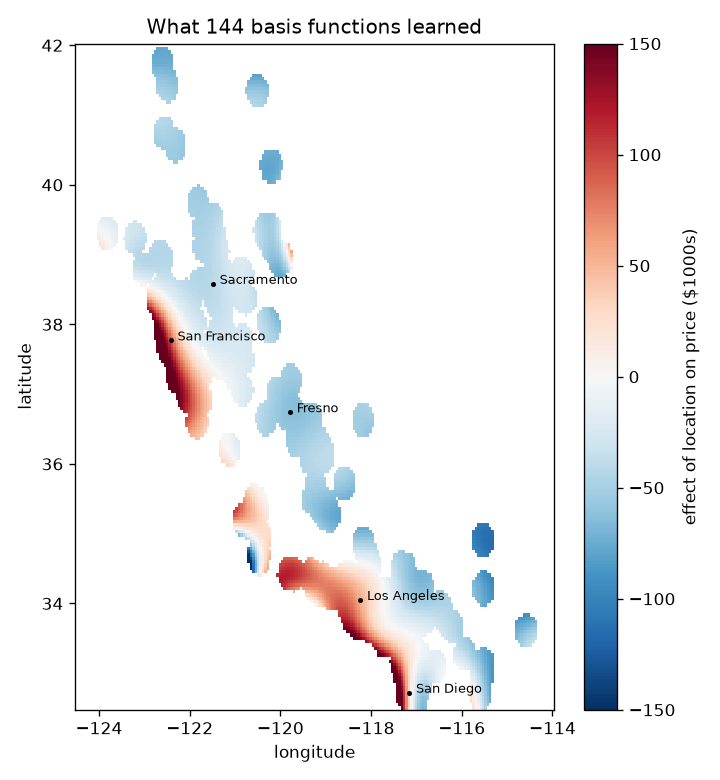

In [13]:
from IPython.display import Image
Image('outputs/price_map.png')

Nobody told the model where the coast is. The bumps learned a strip of high prices along the coast from San Francisco
southwards, and around Los Angeles and San Diego, and lower prices in the Central Valley around Fresno. "Other things
being equal" matters here: the map shows what location adds **after** income, house age and size are taken into account.

## Step 6: write the README and publish

In [14]:
%%writefile README.md
# California house prices

Predicts the median house value of 20,433 California districts (1990 census) with linear regression in PyTorch. The
key idea: 144 Gaussian basis functions over latitude and longitude let a linear model learn a price map of the state.

![map](outputs/price_map.png)

## Results

| model | RMSE |
|---|---|
| always guess the average (validation) | $115.2k |
| linear in 5 district features (validation) | $74.6k |
| + latitude and longitude as plain inputs (validation) | $68.3k |
| + 144 location basis functions, lambda = 0.01 (validation) | $61.4k |
| same, final model on the **test set** | **$61.0k** |

Without regularization (lambda = 0) the least-squares problem has no unique solution: 25 of the basis functions sit
over the ocean or empty desert and never touch a district.

The same model trained with mini-batch SGD and a cosine learning-rate schedule reaches $62.4k in 30 epochs.

## Run it

```bash
pip install -r requirements.txt
python train.py        # compare models, choose lambda, test once (saves model.pt)
python sgd.py          # train the same model with stochastic gradient descent
python price_map.py    # draw the learned location effect
```

## What I learned

- Basis functions make a linear model flexible while keeping an exact, closed-form solution.
- Regularization isn't only against over-fitting: it also makes an ill-posed problem solvable.
- Location alone is worth about +$96k in San Francisco and -$63k in Fresno, other things being equal.

Based on chapter 4 of *Deep Learning: Foundations and Concepts* (Bishop & Bishop, 2024).

Writing README.md


```bash
git add .
git commit -m "California house prices with location basis functions"
git branch -M main
git remote add origin git@github.com:YOUR-USERNAME/house-prices.git
git push -u origin main
```

## Make it yours

- **Width and grid.** Try bump widths `s` of 0.2 and 1.0, and a 20 × 20 grid. When does it start to over-fit, and
  does a larger λ rescue it?
- **Predict the logarithm.** House prices are skewed. Fit `log(value)` instead and compare errors in dollars.
- **The capped districts.** Remove the 985 districts at $500k from training. Does the map change near San Francisco?
- **Ocean proximity.** The raw data has an `ocean_proximity` column. Add it as one-hot features. Does it make the
  location bumps less important?

## On your CV

> **California house-price model** (PyTorch): regularized linear regression with 144 Gaussian location basis functions
> on 20,433 census districts; cut test RMSE to $61k from $115k (mean baseline) and $75k (plain linear model), with closed
> form and mini-batch SGD solutions and a learned price map. github.com/YOUR-USERNAME/house-prices

## Check yourself

- [ ] You can explain why λ = 0 fails here, and why it isn't over-fitting.
- [ ] The test set was used once, after λ was chosen.
- [ ] You can explain why SGD stops short of the exact solution.
- [ ] Your README states the $500k cap and the 1990 date.